In [1]:
%pip install pyspark

In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("NYC Taxi Trip Analysis")
    .master("local[*]")
    .getOrCreate()
)

print("Spark is running!")
print("Spark version:", spark.version)

Spark is running!
Spark version: 4.0.5


In [3]:
numbers = spark.sparkContext.parallelize(
    [10, 20, 30, 40, 50]
)

# Transformation: describe the change
doubled = numbers.map(lambda x: x * 2)

# Action: execute and return results
print(doubled.collect())

[20, 40, 60, 80, 100]


In [4]:
file_path = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2026-01.parquet"

taxi_df = spark.read.parquet(file_path)

print("Taxi data loaded successfully")
taxi_df.show(5, truncate=False)

Taxi data loaded successfully
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|2       |2026-01-01 00:54:04 |2026-01-01 00:59:37  |1              |0.97         |1         |N     

In [5]:
taxi_df.printSchema()

print("Total rows:", taxi_df.count())

print("Total columns:", len(taxi_df.columns))

print("Column names:", taxi_df.columns)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)

Total rows: 3724889
Total columns: 20
Column names: ['VendorID', 'tpep_pick

In [6]:
taxi_df.show(10, truncate=False)
taxi_df.printSchema()
taxi_df.describe().show()

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|2       |2026-01-01 00:54:04 |2026-01-01 00:59:37  |1              |0.97         |1         |N                 |239         |238 

In [7]:
print(taxi_df.columns)

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']


In [8]:
taxi_df.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



In [9]:
from pyspark.sql import functions as F

null_counts = taxi_df.select([
    F.count(
        F.when(F.col(c).isNull(), c)
    ).alias(c)
    for c in taxi_df.columns
])

null_counts.show(truncate=False)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|0       |0                   |0                    |1088058        |0            |1088058   |1088058           |0           |0   

In [10]:
print("Total records:", taxi_df.count())

print("Unique records:", taxi_df.distinct().count())

Total records: 3724889
Unique records: 3724889


In [11]:
taxi_df.select(
    F.min("fare_amount").alias("minimum_fare"),
    F.max("fare_amount").alias("maximum_fare"),
    F.min("trip_distance").alias("minimum_distance"),
    F.max("trip_distance").alias("maximum_distance"),
    F.avg("fare_amount").alias("average_fare"),
    F.avg("trip_distance").alias("average_distance")
).show()

+------------+------------+----------------+----------------+-----------------+-----------------+
|minimum_fare|maximum_fare|minimum_distance|maximum_distance|     average_fare| average_distance|
+------------+------------+----------------+----------------+-----------------+-----------------+
|     -2555.2|      2555.2|             0.0|       269097.48|20.80425389321187|6.455646860884686|
+------------+------------+----------------+----------------+-----------------+-----------------+



In [12]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os

os.listdir('/content/drive/MyDrive')

['Classroom',
 'Drishti_Patel_Resumee (1).pdf',
 'Drishti_Patel_Resumee.pdf',
 'Drishti_Patel_resume (1).pdf',
 'Drishti_Patel_resume.pdf',
 'Resume_DrishtiPatel.pdf',
 'Colab Notebooks',
 'NYC_Taxi_Project']

In [14]:
file_path = "/content/drive/MyDrive/NYC_Taxi_Project/yellow_tripdata_2026-01.parquet"

taxi_df = spark.read.parquet(file_path)

In [15]:
from pyspark.sql import functions as F

taxi_df.select(
    F.sum(
        F.when(F.col("fare_amount") < 0, 1).otherwise(0)
    ).alias("negative_fares"),

    F.sum(
        F.when(F.col("trip_distance") > 100, 1).otherwise(0)
    ).alias("distance_over_100"),

    F.sum(
        F.when(F.col("trip_distance") == 0, 1).otherwise(0)
    ).alias("zero_distance"),

    F.sum(
        F.when(F.col("fare_amount") == 0, 1).otherwise(0)
    ).alias("zero_fares")
).show()

+--------------+-----------------+-------------+----------+
|negative_fares|distance_over_100|zero_distance|zero_fares|
+--------------+-----------------+-------------+----------+
|         39463|              162|       125738|      2082|
+--------------+-----------------+-------------+----------+



In [16]:
taxi_df.select(
    F.count(
        F.when(
            F.col("passenger_count").isNull(), 1
        )
    ).alias("missing_passengers"),

    F.count(
        F.when(
            F.col("RatecodeID").isNull(), 1
        )
    ).alias("missing_ratecode"),

    F.count(
        F.when(
            F.col("Airport_fee").isNull(), 1
        )
    ).alias("missing_airport_fee")
).show()

+------------------+----------------+-------------------+
|missing_passengers|missing_ratecode|missing_airport_fee|
+------------------+----------------+-------------------+
|           1088058|         1088058|            1088058|
+------------------+----------------+-------------------+



In [17]:
taxi_df.filter(
    F.col("passenger_count").isNull() &
    F.col("RatecodeID").isNull() &
    F.col("Airport_fee").isNull()
).count()

1088058

In [18]:
taxi_df.filter(
    F.col("passenger_count").isNull()
).select(
    F.min("tpep_pickup_datetime").alias("first_missing_date"),
    F.max("tpep_pickup_datetime").alias("last_missing_date")
).show()

+-------------------+-------------------+
| first_missing_date|  last_missing_date|
+-------------------+-------------------+
|2026-01-01 00:00:00|2026-01-31 23:59:59|
+-------------------+-------------------+



In [19]:
taxi_df.filter(
    F.col("passenger_count").isNull()
).select(
    F.min("tpep_pickup_datetime").alias("first_missing_date"),
    F.max("tpep_pickup_datetime").alias("last_missing_date")
).show()

+-------------------+-------------------+
| first_missing_date|  last_missing_date|
+-------------------+-------------------+
|2026-01-01 00:00:00|2026-01-31 23:59:59|
+-------------------+-------------------+



In [20]:
taxi_df.select(
    F.min("tpep_pickup_datetime").alias("first_trip_date"),
    F.max("tpep_pickup_datetime").alias("last_trip_date")
).show()

+-------------------+-------------------+
|    first_trip_date|     last_trip_date|
+-------------------+-------------------+
|2025-12-31 23:57:29|2026-02-01 00:45:01|
+-------------------+-------------------+



In [21]:
taxi_df.groupBy(
    F.date_format("tpep_pickup_datetime", "yyyy-MM").alias("trip_month")
).count().orderBy("trip_month").show()

+----------+-------+
|trip_month|  count|
+----------+-------+
|   2025-12|      6|
|   2026-01|3724882|
|   2026-02|      1|
+----------+-------+



In [22]:
taxi_df.filter(
    F.col("passenger_count").isNull()
).select(
    F.count("*").alias("total_missing_records"),
    F.count("fare_amount").alias("records_with_fare"),
    F.count("trip_distance").alias("records_with_distance"),
    F.avg("fare_amount").alias("average_fare"),
    F.avg("trip_distance").alias("average_distance")
).show()

+---------------------+-----------------+---------------------+------------------+------------------+
|total_missing_records|records_with_fare|records_with_distance|      average_fare|  average_distance|
+---------------------+-----------------+---------------------+------------------+------------------+
|              1088058|          1088058|              1088058|25.379336083192374|13.748210113795079|
+---------------------+-----------------+---------------------+------------------+------------------+



In [23]:
taxi_df.filter(
    F.col("fare_amount") < 0
).select(
    "fare_amount",
    "total_amount",
    "trip_distance",
    "payment_type",
    "tpep_pickup_datetime"
).show(10, truncate=False)

+-----------+------------+-------------+------------+--------------------+
|fare_amount|total_amount|trip_distance|payment_type|tpep_pickup_datetime|
+-----------+------------+-------------+------------+--------------------+
|-5.1       |-10.1       |0.63         |4           |2026-01-01 00:54:05 |
|-22.6      |-28.35      |1.92         |4           |2026-01-01 00:43:29 |
|-3.0       |-8.75       |0.02         |4           |2026-01-01 00:37:39 |
|-3.0       |-8.75       |0.03         |4           |2026-01-01 00:01:24 |
|-22.6      |-28.35      |3.12         |2           |2026-01-01 00:10:13 |
|-8.6       |-13.6       |1.03         |4           |2026-01-01 00:33:23 |
|-70.0      |-71.5       |0.01         |3           |2025-12-31 23:57:29 |
|-3.7       |-9.45       |0.14         |3           |2026-01-01 00:01:52 |
|-17.7      |-22.7       |3.63         |2           |2026-01-01 00:24:04 |
|-3.0       |-8.0        |0.01         |4           |2026-01-01 00:30:51 |
+-----------+------------

In [24]:
taxi_df.filter(
    F.col("fare_amount") < 0
).groupBy(
    "payment_type"
).count().orderBy(
    "payment_type"
).show()

+------------+-----+
|payment_type|count|
+------------+-----+
|           0|   32|
|           1|  267|
|           2| 8633|
|           3| 4492|
|           4|26039|
+------------+-----+



In [25]:
taxi_df.filter(
    F.col("trip_distance") == 0
).select(
    "trip_distance",
    "fare_amount",
    "total_amount",
    "payment_type",
    "tpep_pickup_datetime"
).show(10, truncate=False)

+-------------+-----------+------------+------------+--------------------+
|trip_distance|fare_amount|total_amount|payment_type|tpep_pickup_datetime|
+-------------+-----------+------------+------------+--------------------+
|0.0          |3.0        |8.0         |2           |2026-01-01 00:21:36 |
|0.0          |18.4       |24.15       |1           |2026-01-01 00:11:22 |
|0.0          |12.8       |23.15       |1           |2026-01-01 00:54:54 |
|0.0          |50.0       |54.25       |1           |2026-01-01 00:32:10 |
|0.0          |50.0       |54.25       |1           |2026-01-01 00:45:48 |
|0.0          |3.0        |8.75        |2           |2026-01-01 00:56:10 |
|0.0          |5.1        |7.6         |2           |2026-01-01 00:35:40 |
|0.0          |40.0       |41.0        |1           |2026-01-01 00:11:44 |
|0.0          |124.0      |130.0       |1           |2026-01-01 00:40:52 |
|0.0          |60.0       |62.08       |1           |2026-01-01 00:28:16 |
+-------------+----------

In [26]:
taxi_df.filter(
    F.col("trip_distance") == 0
).select(
    F.count("*").alias("zero_distance_records"),
    F.avg("fare_amount").alias("average_fare"),
    F.min("fare_amount").alias("minimum_fare"),
    F.max("fare_amount").alias("maximum_fare")
).show()

+---------------------+------------------+------------+------------+
|zero_distance_records|      average_fare|minimum_fare|maximum_fare|
+---------------------+------------------+------------+------------+
|               125738|27.965839602981266|      -990.0|      2500.0|
+---------------------+------------------+------------+------------+



In [27]:
taxi_df.filter(
    F.col("trip_distance") > 100
).select(
    "trip_distance",
    "fare_amount",
    "total_amount",
    "payment_type",
    "tpep_pickup_datetime"
).orderBy(
    F.col("trip_distance").desc()
).show(10, truncate=False)

+-------------+-----------+------------+------------+--------------------+
|trip_distance|fare_amount|total_amount|payment_type|tpep_pickup_datetime|
+-------------+-----------+------------+------------+--------------------+
|269097.48    |12.19      |16.94       |0           |2026-01-28 01:08:00 |
|237567.19    |72.99      |81.95       |0           |2026-01-30 13:00:00 |
|236216.69    |13.58      |21.33       |0           |2026-01-21 16:31:00 |
|236183.06    |22.75      |34.96       |0           |2026-01-17 10:40:00 |
|221544.91    |31.21      |39.55       |0           |2026-01-02 21:31:00 |
|221436.73    |27.61      |32.36       |0           |2026-01-02 07:07:00 |
|196490.48    |33.59      |38.34       |0           |2026-01-17 10:39:00 |
|192081.68    |60.2       |64.95       |0           |2026-01-29 07:51:00 |
|184908.33    |12.18      |16.93       |0           |2026-01-07 17:51:00 |
|183363.75    |71.01      |75.76       |0           |2026-01-27 14:46:00 |
+-------------+----------

In [28]:
taxi_df.filter(
    F.col("trip_distance") > 100
).select(
    F.min("trip_distance").alias("minimum_suspicious_distance"),
    F.max("trip_distance").alias("maximum_suspicious_distance"),
    F.avg("trip_distance").alias("average_suspicious_distance")
).show()

+---------------------------+---------------------------+---------------------------+
|minimum_suspicious_distance|maximum_suspicious_distance|average_suspicious_distance|
+---------------------------+---------------------------+---------------------------+
|                     100.37|                  269097.48|          70893.20129629629|
+---------------------------+---------------------------+---------------------------+



In [29]:
taxi_df.filter(
    F.col("fare_amount") == 0
).select(
    "fare_amount",
    "total_amount",
    "trip_distance",
    "payment_type",
    "tpep_pickup_datetime"
).show(10, truncate=False)

+-----------+------------+-------------+------------+--------------------+
|fare_amount|total_amount|trip_distance|payment_type|tpep_pickup_datetime|
+-----------+------------+-------------+------------+--------------------+
|0.0        |0.0         |0.5          |4           |2026-01-01 00:40:35 |
|0.0        |-3.25       |0.48         |2           |2026-01-01 00:39:56 |
|0.0        |3.25        |0.48         |2           |2026-01-01 00:39:56 |
|0.0        |0.0         |34.1         |2           |2026-01-01 00:35:58 |
|0.0        |-2.5        |0.0          |2           |2026-01-01 00:24:44 |
|0.0        |2.5         |0.0          |2           |2026-01-01 00:24:44 |
|0.0        |-4.75       |6.16         |2           |2026-01-01 00:30:40 |
|0.0        |4.75        |6.16         |2           |2026-01-01 00:30:40 |
|0.0        |-1.5        |1.4          |2           |2026-01-01 01:04:05 |
|0.0        |1.5         |1.4          |2           |2026-01-01 01:04:05 |
+-----------+------------

In [30]:
taxi_df.filter(
    F.col("fare_amount") == 0
).groupBy(
    "payment_type"
).count().orderBy(
    "payment_type"
).show()

+------------+-----+
|payment_type|count|
+------------+-----+
|           0|  535|
|           1|   23|
|           2| 1207|
|           3|  144|
|           4|  173|
+------------+-----+



In [33]:
taxi_df = taxi_df.withColumn(
    "trip_duration_minutes",
    (
        F.unix_timestamp("tpep_dropoff_datetime") -
        F.unix_timestamp("tpep_pickup_datetime")
    ) / 60
)

taxi_df.select(
    F.min("trip_duration_minutes").alias("minimum_duration"),
    F.max("trip_duration_minutes").alias("maximum_duration"),
    F.avg("trip_duration_minutes").alias("average_duration")
).show()

+----------------+----------------+------------------+
|minimum_duration|maximum_duration|  average_duration|
+----------------+----------------+------------------+
|           -11.7|          7507.9|17.193160337574096|
+----------------+----------------+------------------+



In [34]:
taxi_df.select(
    F.sum(
        F.when(F.col("trip_duration_minutes") <= 0, 1).otherwise(0)
    ).alias("zero_or_negative_duration"),

    F.sum(
        F.when(F.col("trip_duration_minutes") > 24 * 60, 1).otherwise(0)
    ).alias("duration_over_24_hours")
).show()

+-------------------------+----------------------+
|zero_or_negative_duration|duration_over_24_hours|
+-------------------------+----------------------+
|                    45070|                    35|
+-------------------------+----------------------+



In [35]:
taxi_df = taxi_df.withColumn(
    "duration_status",
    F.when(
        F.col("trip_duration_minutes") <= 0,
        "Invalid Duration"
    ).when(
        F.col("trip_duration_minutes") > 1440,
        "Unusually Long Duration"
    ).otherwise(
        "Valid Duration"
    )
)

In [36]:
taxi_df.groupBy("duration_status").count().show()

+--------------------+-------+
|     duration_status|  count|
+--------------------+-------+
|    Invalid Duration|  45070|
|Unusually Long Du...|     35|
|      Valid Duration|3679784|
+--------------------+-------+



In [37]:
cleaned_df = taxi_df.filter(
    (F.col("duration_status") == "Valid Duration") &
    (F.col("trip_distance") <= 100)
)

In [38]:
print("Original records:", taxi_df.count())
print("Cleaned records:", cleaned_df.count())

Original records: 3724889
Cleaned records: 3679623


In [39]:
cleaned_df.select(
    F.min("trip_duration_minutes").alias("minimum_duration"),
    F.max("trip_duration_minutes").alias("maximum_duration"),
    F.min("trip_distance").alias("minimum_distance"),
    F.max("trip_distance").alias("maximum_distance")
).show()

+--------------------+----------------+----------------+----------------+
|    minimum_duration|maximum_duration|minimum_distance|maximum_distance|
+--------------------+----------------+----------------+----------------+
|0.016666666666666666|         1439.55|             0.0|           99.93|
+--------------------+----------------+----------------+----------------+



In [40]:
cleaned_df.select(
    F.count("*").alias("total_trips"),
    F.round(F.avg("fare_amount"), 2).alias("average_fare"),
    F.round(F.avg("total_amount"), 2).alias("average_total_amount"),
    F.round(F.avg("trip_distance"), 2).alias("average_distance"),
    F.round(F.avg("trip_duration_minutes"), 2).alias("average_duration"),
    F.round(F.sum("total_amount"), 2).alias("total_revenue")
).show()

+-----------+------------+--------------------+----------------+----------------+--------------+
|total_trips|average_fare|average_total_amount|average_distance|average_duration| total_revenue|
+-----------+------------+--------------------+----------------+----------------+--------------+
|    3679623|       20.86|               29.22|            3.38|           17.38|1.0751478705E8|
+-----------+------------+--------------------+----------------+----------------+--------------+



In [41]:
payment_analysis = cleaned_df.groupBy("payment_type").agg(
    F.count("*").alias("total_trips"),
    F.round(F.avg("total_amount"), 2).alias("average_payment"),
    F.round(F.sum("total_amount"), 2).alias("total_revenue")
).orderBy(F.desc("total_trips"))

payment_analysis.show()

+------------+-----------+---------------+-------------+
|payment_type|total_trips|average_payment|total_revenue|
+------------+-----------+---------------+-------------+
|           1|    2210528|          29.67|6.558935935E7|
|           0|    1087889|          31.68|3.446548646E7|
|           2|     308826|          23.42|    7233811.3|
|           4|      56194|           1.56|     87578.48|
|           3|      16186|           8.56|    138551.46|
+------------+-----------+---------------+-------------+



In [42]:
passenger_analysis = cleaned_df.groupBy("passenger_count").agg(
    F.count("*").alias("total_trips"),
    F.round(F.avg("total_amount"), 2).alias("average_payment")
).orderBy("passenger_count")

passenger_analysis.show()

+---------------+-----------+---------------+
|passenger_count|total_trips|average_payment|
+---------------+-----------+---------------+
|           NULL|    1087889|          31.68|
|              0|      14678|          24.74|
|              1|    2114003|          27.52|
|              2|     328389|          31.09|
|              3|      71523|           30.8|
|              4|      49087|          35.35|
|              5|       9160|          25.87|
|              6|       4887|          26.82|
|              7|          2|          183.5|
|              8|          4|          96.99|
|              9|          1|          98.75|
+---------------+-----------+---------------+



In [43]:
distance_analysis = cleaned_df.withColumn(
    "distance_category",
    F.when(F.col("trip_distance") <= 2, "Short Trip (0-2 miles)")
    .when(F.col("trip_distance") <= 5, "Medium Trip (2-5 miles)")
    .when(F.col("trip_distance") <= 10, "Long Trip (5-10 miles)")
    .otherwise("Very Long Trip (Above 10 miles)")
)

distance_analysis.groupBy("distance_category").agg(
    F.count("*").alias("total_trips"),
    F.round(F.avg("trip_distance"), 2).alias("average_distance"),
    F.round(F.avg("total_amount"), 2).alias("average_payment"),
    F.round(F.sum("total_amount"), 2).alias("total_revenue")
).orderBy("average_distance").show(truncate=False)

+-------------------------------+-----------+----------------+---------------+-------------+
|distance_category              |total_trips|average_distance|average_payment|total_revenue|
+-------------------------------+-----------+----------------+---------------+-------------+
|Short Trip (0-2 miles)         |1994875    |1.06            |19.57          |3.904065663E7|
|Medium Trip (2-5 miles)        |996360     |3.09            |29.27          |2.916598011E7|
|Long Trip (5-10 miles)         |410939     |7.16            |44.45          |1.826764801E7|
|Very Long Trip (Above 10 miles)|277449     |15.59           |75.84          |2.10405023E7 |
+-------------------------------+-----------+----------------+---------------+-------------+



In [44]:
hourly_analysis = cleaned_df.withColumn(
    "pickup_hour",
    F.hour("tpep_pickup_datetime")
)

hourly_analysis.groupBy("pickup_hour").agg(
    F.count("*").alias("total_trips"),
    F.round(F.avg("total_amount"), 2).alias("average_payment"),
    F.round(F.sum("total_amount"), 2).alias("total_revenue")
).orderBy("pickup_hour").show(24)

+-----------+-----------+---------------+-------------+
|pickup_hour|total_trips|average_payment|total_revenue|
+-----------+-----------+---------------+-------------+
|          0|     110902|          29.54|   3276471.33|
|          1|      77091|          28.94|   2231033.88|
|          2|      53625|           27.5|   1474629.01|
|          3|      38336|          27.92|   1070178.62|
|          4|      28486|          31.21|    889146.33|
|          5|      32733|          33.93|   1110581.69|
|          6|      63153|          32.61|   2059350.06|
|          7|     112070|          31.06|   3480672.12|
|          8|     146223|          29.84|   4363572.07|
|          9|     154614|          27.94|   4319638.58|
|         10|     159063|          27.35|    4350203.7|
|         11|     169318|          27.07|   4583892.01|
|         12|     184908|          27.54|   5092109.98|
|         13|     192884|          27.93|    5388027.0|
|         14|     204524|          29.14|   5959

In [45]:
pickup_analysis = cleaned_df.groupBy("PULocationID").agg(
    F.count("*").alias("total_pickups"),
    F.round(F.avg("total_amount"), 2).alias("average_payment"),
    F.round(F.sum("total_amount"), 2).alias("total_revenue")
).orderBy(F.desc("total_pickups"))

pickup_analysis.show(10)

+------------+-------------+---------------+-------------+
|PULocationID|total_pickups|average_payment|total_revenue|
+------------+-------------+---------------+-------------+
|         237|       157020|          21.42|    3363881.4|
|         132|       151332|          72.37|1.095167407E7|
|         236|       150143|          22.43|   3367179.55|
|         161|       144212|          26.34|   3799153.76|
|         186|       108893|          25.21|   2745320.69|
|         142|       107900|           23.1|   2492818.27|
|         162|       106983|           25.4|    2717135.3|
|         230|       104783|          28.92|   3030656.59|
|          79|       100235|          24.97|   2502681.39|
|         239|        95689|          23.31|   2230328.08|
+------------+-------------+---------------+-------------+
only showing top 10 rows


In [46]:
dropoff_analysis = cleaned_df.groupBy("DOLocationID").agg(
    F.count("*").alias("total_dropoffs"),
    F.round(F.avg("total_amount"), 2).alias("average_payment"),
    F.round(F.sum("total_amount"), 2).alias("total_revenue")
).orderBy(F.desc("total_dropoffs"))

dropoff_analysis.show(10)

+------------+--------------+---------------+-------------+
|DOLocationID|total_dropoffs|average_payment|total_revenue|
+------------+--------------+---------------+-------------+
|         236|        153745|          22.82|   3507948.52|
|         237|        144083|          22.09|   3182227.44|
|         161|        119693|          25.95|   3105681.18|
|         170|         98330|          25.32|   2490163.33|
|         230|         97810|          30.99|   3030861.94|
|         142|         96035|          24.03|    2307881.6|
|         239|         95709|           24.8|   2373304.98|
|         141|         94405|          23.87|   2253627.45|
|          68|         89389|          26.86|   2400724.22|
|          79|         88282|          26.19|   2312395.66|
+------------+--------------+---------------+-------------+
only showing top 10 rows


In [47]:
tip_analysis = cleaned_df.groupBy("payment_type").agg(
    F.count("*").alias("total_trips"),
    F.round(F.avg("tip_amount"), 2).alias("average_tip"),
    F.round(F.sum("tip_amount"), 2).alias("total_tips")
).orderBy(F.desc("total_tips"))

tip_analysis.show()

+------------+-----------+-----------+----------+
|payment_type|total_trips|average_tip|total_tips|
+------------+-----------+-----------+----------+
|           1|    2210528|       4.14|9148242.28|
|           0|    1087889|       0.38| 408054.67|
|           2|     308826|        0.0|    131.29|
|           4|      56194|        0.0|      10.1|
|           3|      16186|        0.0|       0.0|
+------------+-----------+-----------+----------+



In [48]:
tip_summary = cleaned_df.select(
    F.round(F.sum("tip_amount"), 2).alias("total_tips"),
    F.round(F.sum("fare_amount"), 2).alias("total_fare"),
    F.round(
        (F.sum("tip_amount") / F.sum("fare_amount")) * 100,
        2
    ).alias("tip_percentage")
)

tip_summary.show()

+----------+-------------+--------------+
|total_tips|   total_fare|tip_percentage|
+----------+-------------+--------------+
|9556438.34|7.674000584E7|         12.45|
+----------+-------------+--------------+



In [49]:
cleaned_df.createOrReplaceTempView("nyc_taxi")

In [50]:
spark.sql("""
SELECT COUNT(*) AS total_trips
FROM nyc_taxi
""").show()

+-----------+
|total_trips|
+-----------+
|    3679623|
+-----------+



In [51]:
spark.sql("""
SELECT
    COUNT(*) AS total_trips,
    ROUND(AVG(fare_amount), 2) AS average_fare,
    ROUND(AVG(total_amount), 2) AS average_payment,
    ROUND(AVG(trip_distance), 2) AS average_distance,
    ROUND(AVG(trip_duration_minutes), 2) AS average_duration,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM nyc_taxi
""").show()

+-----------+------------+---------------+----------------+----------------+--------------+
|total_trips|average_fare|average_payment|average_distance|average_duration| total_revenue|
+-----------+------------+---------------+----------------+----------------+--------------+
|    3679623|       20.86|          29.22|            3.38|           17.38|1.0751478705E8|
+-----------+------------+---------------+----------------+----------------+--------------+



In [52]:
spark.sql("""
SELECT
    payment_type,
    COUNT(*) AS total_trips,
    ROUND(AVG(total_amount), 2) AS average_payment,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM nyc_taxi
GROUP BY payment_type
ORDER BY total_trips DESC
""").show()

+------------+-----------+---------------+-------------+
|payment_type|total_trips|average_payment|total_revenue|
+------------+-----------+---------------+-------------+
|           1|    2210528|          29.67|6.558935935E7|
|           0|    1087889|          31.68|3.446548646E7|
|           2|     308826|          23.42|    7233811.3|
|           4|      56194|           1.56|     87578.48|
|           3|      16186|           8.56|    138551.46|
+------------+-----------+---------------+-------------+



In [53]:
spark.sql("""
SELECT
    HOUR(tpep_pickup_datetime) AS pickup_hour,
    COUNT(*) AS total_trips,
    ROUND(AVG(total_amount), 2) AS average_payment,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM nyc_taxi
GROUP BY HOUR(tpep_pickup_datetime)
ORDER BY pickup_hour
""").show(24)

+-----------+-----------+---------------+-------------+
|pickup_hour|total_trips|average_payment|total_revenue|
+-----------+-----------+---------------+-------------+
|          0|     110902|          29.54|   3276471.33|
|          1|      77091|          28.94|   2231033.88|
|          2|      53625|           27.5|   1474629.01|
|          3|      38336|          27.92|   1070178.62|
|          4|      28486|          31.21|    889146.33|
|          5|      32733|          33.93|   1110581.69|
|          6|      63153|          32.61|   2059350.06|
|          7|     112070|          31.06|   3480672.12|
|          8|     146223|          29.84|   4363572.07|
|          9|     154614|          27.94|   4319638.58|
|         10|     159063|          27.35|    4350203.7|
|         11|     169318|          27.07|   4583892.01|
|         12|     184908|          27.54|   5092109.98|
|         13|     192884|          27.93|    5388027.0|
|         14|     204524|          29.14|   5959

In [54]:
filtered_taxi = cleaned_df.filter(
    F.col("total_amount") > 50
)

In [55]:
filtered_taxi.count()

414235

In [56]:
high_value_trips = cleaned_df.filter(
    F.col("total_amount") > 100
)

print("Transformation created successfully")

Transformation created successfully


In [57]:
high_value_trips.show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+---------------------+---------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|trip_duration_minutes|duration_status|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+---------------------+---------------+
|       1| 2026-

In [58]:
high_value_trips.cache()

high_value_trips.count()

60730

In [59]:
high_value_trips.groupBy("payment_type").count().show()

+------------+-----+
|payment_type|count|
+------------+-----+
|           1|51674|
|           3|  154|
|           2| 2531|
|           4|  567|
|           0| 5804|
+------------+-----+



In [60]:
print("Number of partitions:", cleaned_df.rdd.getNumPartitions())

Number of partitions: 2


In [61]:
repartitioned_df = cleaned_df.repartition(4)

print("Original partitions:", cleaned_df.rdd.getNumPartitions())
print("New partitions:", repartitioned_df.rdd.getNumPartitions())

Original partitions: 2
New partitions: 4


In [62]:
coalesced_df = repartitioned_df.coalesce(2)

print("Before coalesce:", repartitioned_df.rdd.getNumPartitions())
print("After coalesce:", coalesced_df.rdd.getNumPartitions())

Before coalesce: 4
After coalesce: 2


In [63]:
output_path = "/content/drive/MyDrive/NYC_Taxi_Project/cleaned_taxi_data"

cleaned_df.write \
    .mode("overwrite") \
    .parquet(output_path)

print("Cleaned data saved successfully!")

Cleaned data saved successfully!


In [64]:
saved_df = spark.read.parquet(output_path)

print("Total records:", saved_df.count())

saved_df.printSchema()

Total records: 3679623
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)
 |-- trip_duration_minutes: double (nullable = true)


In [65]:
saved_df.createOrReplaceTempView("saved_nyc_taxi")

spark.sql("""
SELECT
    COUNT(*) AS total_trips,
    ROUND(AVG(total_amount), 2) AS average_payment,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM saved_nyc_taxi
""").show()

+-----------+---------------+--------------+
|total_trips|average_payment| total_revenue|
+-----------+---------------+--------------+
|    3679623|          29.22|1.0751478705E8|
+-----------+---------------+--------------+



##Data Visualization

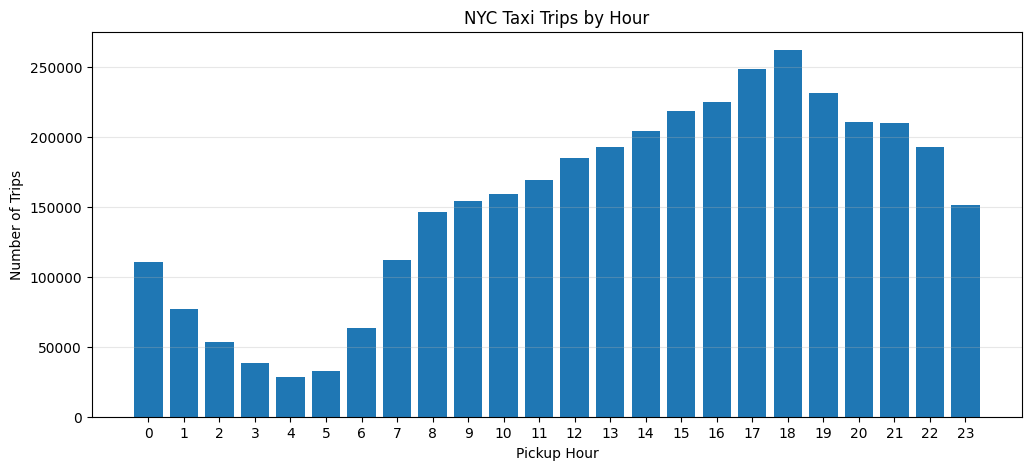

In [68]:
import matplotlib.pyplot as plt

hourly_data = cleaned_df.groupBy(
    F.hour("tpep_pickup_datetime").alias("pickup_hour")
).count().orderBy("pickup_hour").toPandas()

plt.figure(figsize=(12, 5))
plt.bar(hourly_data["pickup_hour"], hourly_data["count"])

plt.title("NYC Taxi Trips by Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

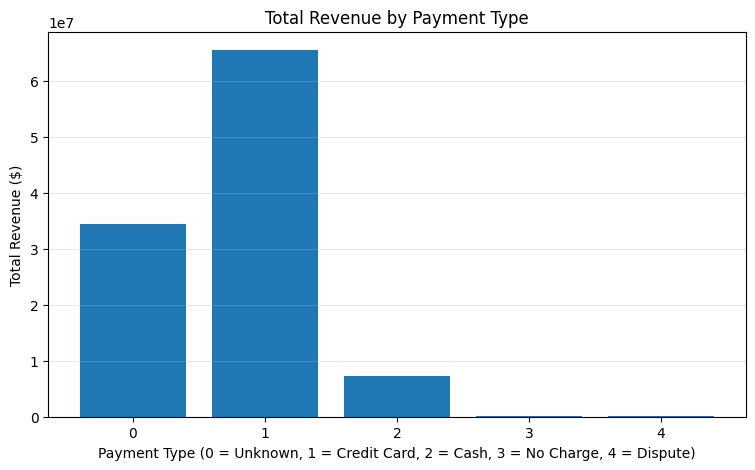

In [69]:
payment_data = cleaned_df.groupBy("payment_type").agg(
    F.sum("total_amount").alias("total_revenue")
).orderBy("payment_type").toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    payment_data["payment_type"].astype(str),
    payment_data["total_revenue"]
)

plt.title("Total Revenue by Payment Type")
plt.xlabel("Payment Type (0 = Unknown, 1 = Credit Card, 2 = Cash, 3 = No Charge, 4 = Dispute)")
plt.ylabel("Total Revenue ($)")
plt.grid(axis="y", alpha=0.3)

plt.show()

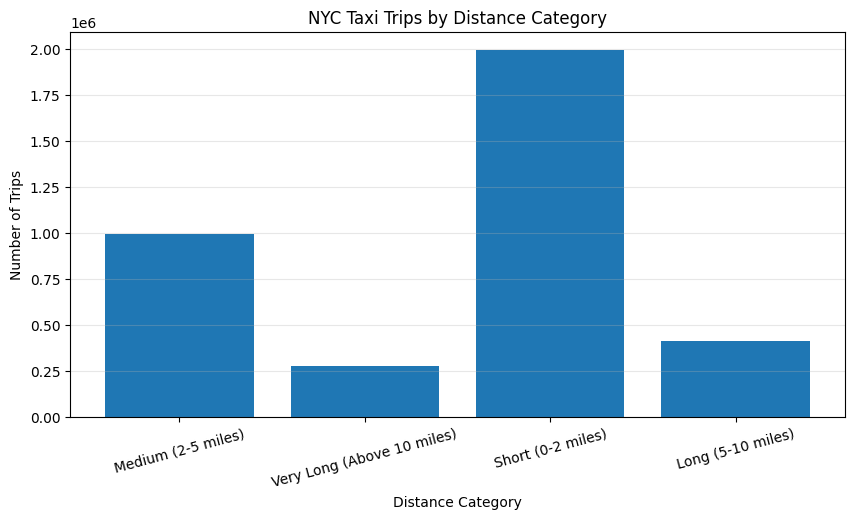

In [70]:
distance_data = cleaned_df.withColumn(
    "distance_category",
    F.when(F.col("trip_distance") <= 2, "Short (0-2 miles)")
     .when(F.col("trip_distance") <= 5, "Medium (2-5 miles)")
     .when(F.col("trip_distance") <= 10, "Long (5-10 miles)")
     .otherwise("Very Long (Above 10 miles)")
).groupBy("distance_category").count().toPandas()

plt.figure(figsize=(10, 5))
plt.bar(
    distance_data["distance_category"],
    distance_data["count"]
)

plt.title("NYC Taxi Trips by Distance Category")
plt.xlabel("Distance Category")
plt.ylabel("Number of Trips")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

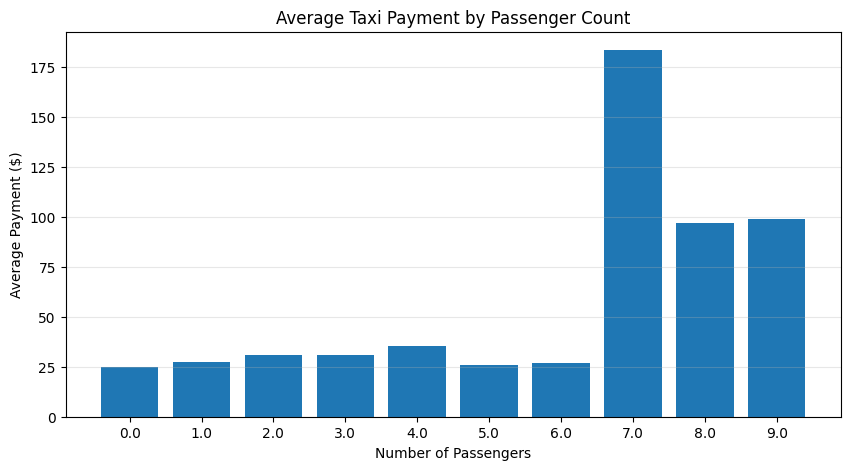

In [71]:
passenger_data = cleaned_df.groupBy("passenger_count").agg(
    F.avg("total_amount").alias("average_payment")
).orderBy("passenger_count").toPandas()

passenger_data = passenger_data.dropna()

plt.figure(figsize=(10, 5))
plt.bar(
    passenger_data["passenger_count"].astype(str),
    passenger_data["average_payment"]
)

plt.title("Average Taxi Payment by Passenger Count")
plt.xlabel("Number of Passengers")
plt.ylabel("Average Payment ($)")
plt.grid(axis="y", alpha=0.3)

plt.show()

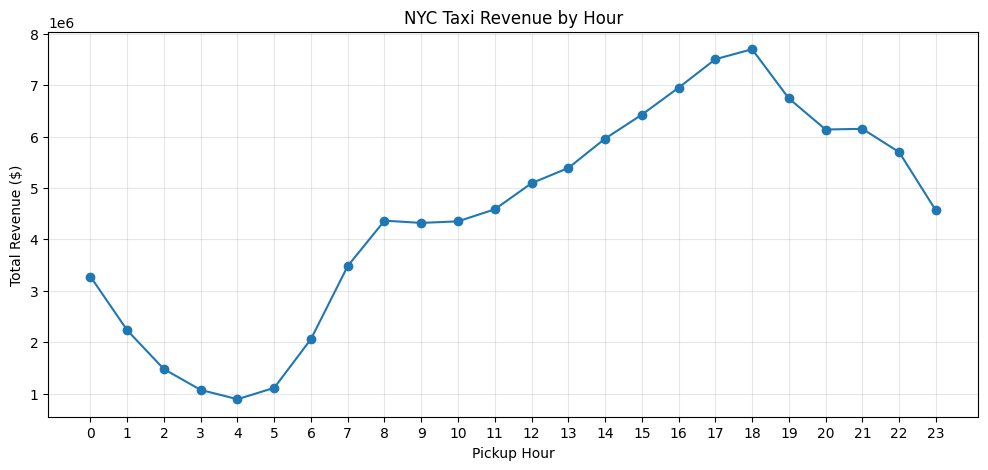

In [72]:
revenue_hourly = cleaned_df.groupBy(
    F.hour("tpep_pickup_datetime").alias("pickup_hour")
).agg(
    F.sum("total_amount").alias("total_revenue")
).orderBy("pickup_hour").toPandas()

plt.figure(figsize=(12, 5))
plt.plot(
    revenue_hourly["pickup_hour"],
    revenue_hourly["total_revenue"],
    marker="o"
)

plt.title("NYC Taxi Revenue by Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Total Revenue ($)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()